## 02 - Visualizing Run A (Paper's Gene List, n=150, k=9)

### Aim
* Visualize the two inputs/outputs behind Run A (`01_restrict_to_panCanAtlas_cohort_k9.ipynb`, Step 6) - the
  XDec rerun on the n=150 PanCanAtlas cohort using the paper's own 282-gene Table S3 list instead of this
  project's 344-gene Stage-0 list: (1) the Peng et al. reference's own expression for that gene list, (2) the
  gene-level correlation between those reference cells and Run A's 9 estimated profiles. Both figures sort
  their reference axis (cells in Figure 1, pseudo-bulks in Figure 2) into a fixed **biological-compartment**
  order - pancreatic epithelium (acinar, ductal, enteroendocrine) -> stroma (stellate, fibroblast,
  endothelial, neural) -> immune (T cell, B lineage, myeloid) - rather than alphabetically or by clustering,
  so related cell types sit next to each other; Figure 1 still clusters genes (rows) and Figure 2 keeps
  profiles in fixed `Profile_1..9` order.

### Input
* `data/deconvolution/xdec/gene_lists/xdec_chi_table_s3_genes.txt` - the paper's 282-gene Table S3 list.
* `data/deconvolution/xdec/{refs.tsv, ref_metadata.tsv}` - Peng et al. 2019 single-cell reference (notebook 04).
* `data/deconvolution/xdec/stage1_with_refs_k9_n150_paperGenes/cell_type_profiles.tsv` - Run A's 9 estimated
  profiles (Stage 1 output, paper's gene list, n=150, k=9).

### Output
* `data/deconvolution/xdec/figures/fig_run_a_reference_expression_clustermap.png` - z-scored heatmap of
  reference single-cell expression over the paper's gene list, genes clustered, cells sorted into fixed
  biological-compartment cell-type blocks.
* `data/deconvolution/xdec/figures/fig_run_a_profile_reference_correlation_clustermap.png` - heatmap of
  Spearman correlation between Run A's 9 profiles (fixed order) and reference pseudo-bulks, pseudo-bulks
  sorted into the same fixed biological-compartment cell-type blocks.

### Steps
1. Restrict the paper's 282-gene list to genes present in both `refs.tsv` and Run A's `cell_type_profiles.tsv`
   (247/282 recovered).
2. Define a fixed cell-type order (`cell_type_order`) grouping the 10 reference types into three biological
   compartments - pancreatic epithelium, stroma, immune - instead of alphabetical order; reuse it for both
   figures' column colors, legends, and sort keys.
3. Figure 1: z-score each gene's expression across all reference single cells, plot as a `seaborn.clustermap`
   with genes (rows) hierarchically clustered and cells (columns) sorted by `cell_type_order` (not clustered).
4. Figure 2: average reference single cells into (patient, cell type) pseudo-bulks, Spearman-correlate each of
   Run A's 9 profiles against every pseudo-bulk, plot as a `seaborn.clustermap` with pseudo-bulks (columns)
   sorted by the same `cell_type_order` (not clustered) and profiles (rows) left in fixed `Profile_1..9` order.

### Result
* **Figure 1**: with cells sorted into compartment blocks, most of the 10 types show a contiguous band of
  genes elevated (dark red) only within that type's column block - pancreatic acinar, pancreatic ductal,
  enteroendocrine, fibroblast, blood vessel endothelial, myeloid leukocyte, and lymphocyte of B lineage each
  have at least one visually distinct marker-gene band, and grouping by compartment puts the two true
  epithelial blocks (acinar, ductal) and the two lymphoid blocks (T cell, B lineage) directly adjacent. T
  cell, pancreatic stellate, and neural - the hardest-to-separate or smallest blocks - lack a clean dedicated
  band, consistent with the lymphoid/stromal confusability already established elsewhere in this project
  (notebooks 09/10).
* **Figure 2**: with pseudo-bulks sorted into the same compartment blocks, **Profile_8's row is visibly dark
  across essentially every block** - it has the highest mean correlation against every single reference
  pseudo-bulk (mean r=0.294, vs. 0.15 or lower for every other profile), narrowly ranging 0.19 (acinar) to
  0.42 (T cell). **Profile_1** and **Profile_3** are both broadly elevated across most blocks, with Profile_1
  additionally showing a sharp extra peak over the pancreatic ductal block (mean r=0.35) that the others
  lack. **Profile_6** and **Profile_7** each carry one narrow, cell-type-specific peak - over the
  enteroendocrine and pancreatic acinar blocks respectively, now immediately adjacent in the epithelial
  compartment - that was invisible under column clustering. Profiles 2, 4, and 5 share a broad elevation over
  the stromal/immune blocks (fibroblast, endothelial, B lineage, myeloid); Profile_9 stays pale across every
  block.

### Conclusion
* Figure 2 is a direct visual confirmation of Step 6's numeric finding in `01_restrict_to_panCanAtlas_cohort_
  k9.ipynb`: Profile_8 is Run A's non-specific "catch-all" profile (the one most broadly correlated with
  essentially everything), the same role Profile_7 played in the original 344-gene baseline. Using the
  paper's own gene list did not eliminate this component, it only relabeled which profile carries it - its
  uniformly dark row is immediately visible once pseudo-bulks are grouped into biological-compartment blocks,
  without needing column clustering to group it with anything else.


In [1]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# This notebook lives in progress/paper_duplication/; Jupyter starts the kernel with
# cwd = the notebook's own folder, and every "data/..." path below is relative to progress/.
if os.path.basename(os.getcwd()) == "paper_duplication":
    os.chdir("..")

XDEC_DIR = "data/deconvolution/xdec"
FIG_DIR = os.path.join(XDEC_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

RUN_A_STAGE1_DIR = os.path.join(XDEC_DIR, "stage1_with_refs_k9_n150_paperGenes")

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

# Single-hue sequential blue ramp (magnitude encoding), light -> dark - matches this
# project's other publication-style figures (notebook 10, notebook paper_duplication/01).
SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)

os.getcwd()


'/Users/liruixi/Desktop/i20_transfer/QCB/rotation/Alex/XDec_Pancreatic_Cancer/progress'

### Step 1: restrict the paper's gene list to genes present in the reference and in Run A's profiles

In [2]:
paper_genes = [l.strip() for l in open(os.path.join(XDEC_DIR, "gene_lists", "xdec_chi_table_s3_genes.txt")) if l.strip()]

refs = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)
cell_profiles_a = pd.read_csv(os.path.join(RUN_A_STAGE1_DIR, "cell_type_profiles.tsv"), sep="\t", index_col=0)

genes = [g for g in paper_genes if g in refs.index and g in cell_profiles_a.index]
print(f"{len(genes)}/{len(paper_genes)} of the paper's genes present in both refs.tsv and Run A's cell_type_profiles.tsv")

ref_cell_types = ref_meta.loc[refs.columns, "Cell_Type"]

# Fixed biological-compartment order (not alphabetical) so visually/functionally related cell types sit
# next to each other: pancreatic epithelial/parenchymal, then stroma, then immune. Within each compartment
# the three literally "pancreatic"-named types (acinar, ductal, stellate) stay close to their true lineage
# neighbors rather than being forced into one block regardless of biology.
cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",   # pancreatic epithelium
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",  # stroma
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",                     # immune
]
assert set(cell_type_order) == set(ref_cell_types.unique()), "cell_type_order must cover every reference cell type"
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", n_colors=len(cell_type_order))))


247/282 of the paper's genes present in both refs.tsv and Run A's cell_type_profiles.tsv


### Step 2: Figure 1 - reference expression over the shared gene list, z-scored, columns sorted by biological compartment

Each gene (row) is z-scored across all 2,748 reference single cells before plotting (standard for
marker-gene heatmaps, matching notebook 11's method) - this puts every gene on the same scale so a cell
type's signature is visible as a block of warm color regardless of that gene's absolute expression level.
Genes (rows) are hierarchically clustered purely for visual grouping of co-expressed genes. Cells (columns)
are sorted into fixed blocks by `cell_type_order` - never reordered by clustering - grouping the 10 reference
types into three biological compartments (pancreatic epithelium, stroma, immune) so e.g. the two epithelial
types (acinar, ductal) and the two lymphoid types (T cell, B lineage) sit next to each other.

247/247 genes kept after dropping zero-variance rows


/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


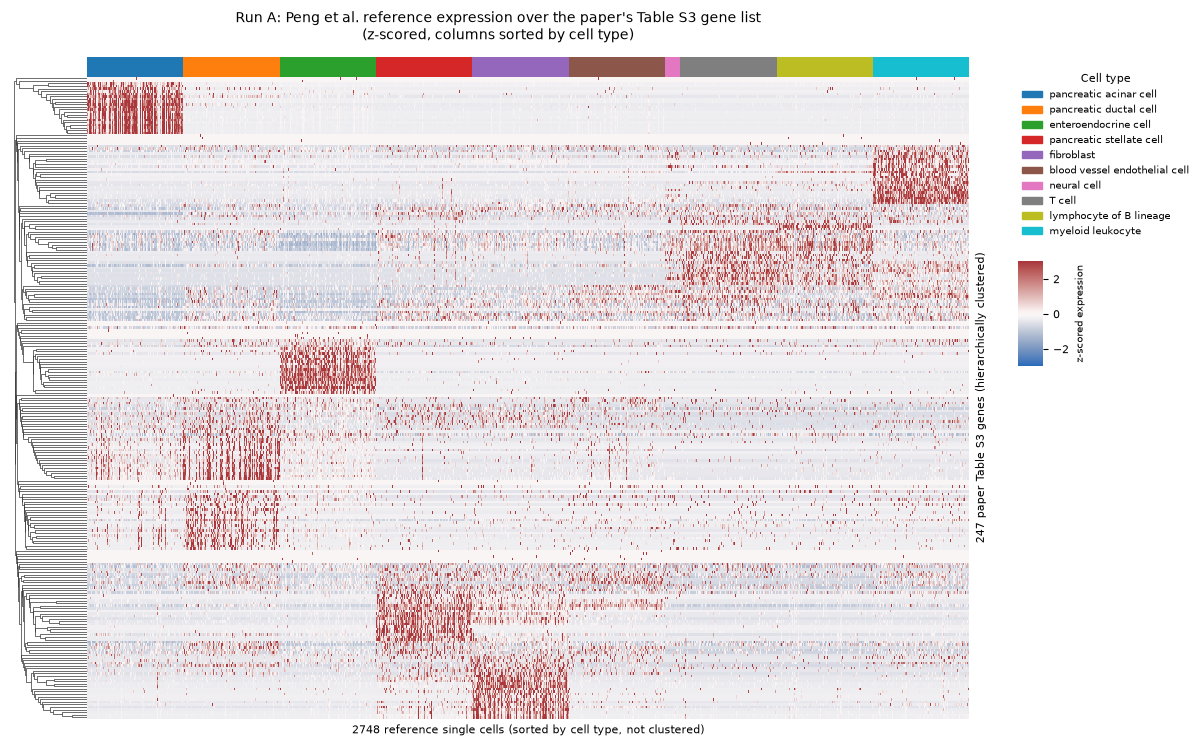

saved data/deconvolution/xdec/figures/fig_run_a_reference_expression_clustermap.png


In [3]:
expr = refs.loc[genes]
zscored = expr.sub(expr.mean(axis=1), axis=0).div(expr.std(axis=1).replace(0, np.nan), axis=0)
zscored = zscored.dropna(how="any")
print(f"{zscored.shape[0]}/{len(genes)} genes kept after dropping zero-variance rows")

col_types = pd.Categorical(ref_cell_types.loc[zscored.columns], categories=cell_type_order, ordered=True)
col_order = pd.Series(col_types, index=zscored.columns).sort_values(kind="stable").index
zscored = zscored[col_order]

col_colors = ref_cell_types.loc[zscored.columns].map(cell_palette)
col_colors.name = "Cell type"

g1 = sns.clustermap(
    zscored, row_cluster=True, col_cluster=False,
    col_colors=col_colors.values,
    cmap="vlag", vmin=-3, vmax=3, center=0,
    xticklabels=False, yticklabels=False,
    figsize=(10, 7), cbar_kws={"label": "z-scored expression"},
    dendrogram_ratio=(0.08, 0.02),
)
g1.ax_heatmap.set_xlabel(f"{zscored.shape[1]} reference single cells (sorted by cell type, not clustered)")
g1.ax_heatmap.set_ylabel(f"{zscored.shape[0]} paper Table S3 genes (hierarchically clustered)")
handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend1 = g1.ax_heatmap.legend(handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
                                loc="upper left", fontsize=7, title_fontsize=8, frameon=False)
g1.fig.suptitle("Run A: Peng et al. reference expression over the paper's Table S3 gene list\n(z-scored, columns sorted by cell type)",
                 y=1.03, fontsize=10)

# Move the colorbar from its default top-left spot to directly below the cell-type legend, left-aligned
# with it (same x0), using the legend's actual rendered left edge rather than a hardcoded coordinate.
g1.cax.yaxis.label.set_fontsize(7)
g1.fig.canvas.draw()
legend_bbox = legend1.get_window_extent(g1.fig.canvas.get_renderer()).transformed(g1.fig.transFigure.inverted())
cbar_width, cbar_height, gap = 0.025, 0.15, 0.03
g1.cax.set_position([legend_bbox.x0, legend_bbox.y0 - gap - cbar_height, cbar_width, cbar_height])

fig1_path = os.path.join(FIG_DIR, "fig_run_a_reference_expression_clustermap.png")
g1.savefig(fig1_path, dpi=200, bbox_inches="tight")
plt.show()
print("saved", fig1_path)


### Step 3: Figure 2 - Run A profiles vs. reference pseudo-bulks, gene-level granularity

Matching the gene-level approach used elsewhere in this project (notebook 10's Figure 2A duplicate): single
cells are averaged into one pseudo-bulk per (patient, cell type) pair over the shared gene list, then each of
Run A's 9 estimated profiles (`cell_type_profiles.tsv`) is Spearman-correlated against every pseudo-bulk
individually. Matching Figure 1's convention: pseudo-bulks (columns) are sorted into the same `cell_type_order`
biological-compartment blocks - never reordered by clustering - so every pseudo-bulk from the same cell type,
and every cell type from the same compartment, sits together; profiles (rows) are left in fixed
`Profile_1..9` order.

2748 single cells -> 270 (patient x cell type) pseudo-bulk references
correlation matrix (Run A profiles x pseudo-bulks): (9, 270)


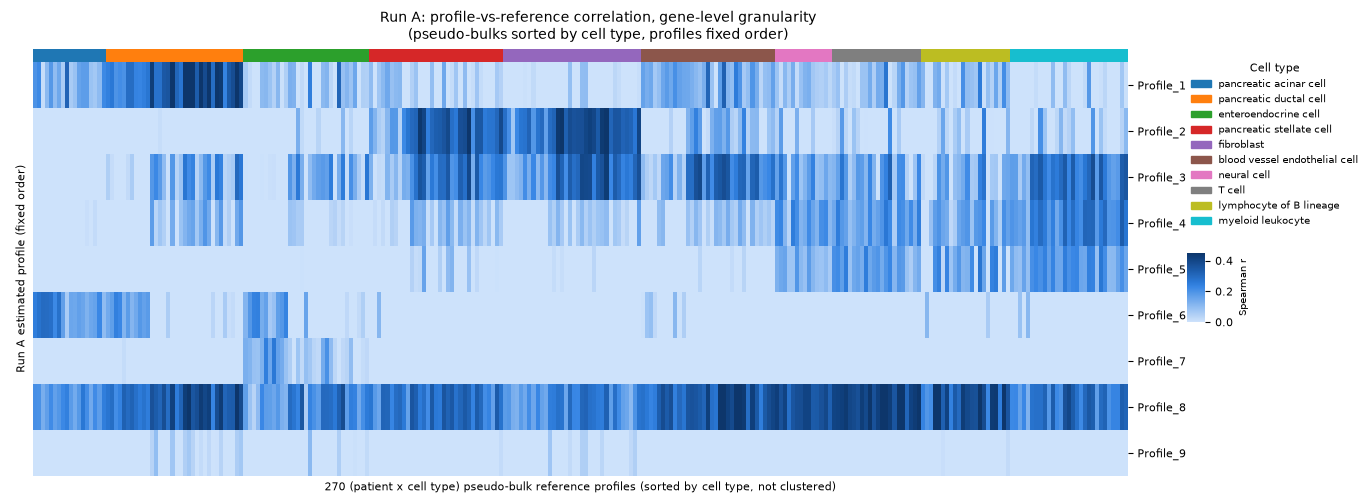

saved data/deconvolution/xdec/figures/fig_run_a_profile_reference_correlation_clustermap.png


In [4]:
ref_sub = refs.loc[genes]
patients = pd.Series(ref_sub.columns, index=ref_sub.columns).str.split("_").str[0]
group_key = patients.astype(str) + " | " + ref_cell_types.astype(str)
pseudobulk = ref_sub.T.groupby(group_key).mean().T
pb_cell_types = pd.Series({c: c.split(" | ")[1] for c in pseudobulk.columns})
print(f"{ref_sub.shape[1]} single cells -> {pseudobulk.shape[1]} (patient x cell type) pseudo-bulk references")

profile_order = [f"Profile_{i}" for i in range(1, 10)]
combined = pd.concat([pseudobulk, cell_profiles_a.loc[genes, profile_order]], axis=1)
corr_full = combined.corr(method="spearman")
corr_a = corr_full.loc[profile_order, pseudobulk.columns]
print("correlation matrix (Run A profiles x pseudo-bulks):", corr_a.shape)

pb_types = pd.Categorical(pb_cell_types, categories=cell_type_order, ordered=True)
pb_col_order = pd.Series(pb_types, index=pb_cell_types.index).sort_values(kind="stable").index
corr_a = corr_a[pb_col_order]

pb_col_colors = pb_cell_types.loc[corr_a.columns].map(cell_palette)
pb_col_colors.name = "Cell type"

g2 = sns.clustermap(
    corr_a, row_cluster=False, col_cluster=False,
    col_colors=pb_col_colors.values,
    cmap=seq_blue, vmin=0, vmax=float(np.percentile(corr_a.values, 99)),
    xticklabels=False, yticklabels=True,
    figsize=(12, 4.6), cbar_kws={"label": "Spearman r"},
    dendrogram_ratio=(0.02, 0.02),
)
g2.ax_heatmap.set_xlabel(f"{corr_a.shape[1]} (patient x cell type) pseudo-bulk reference profiles (sorted by cell type, not clustered)")
g2.ax_heatmap.set_ylabel("Run A estimated profile (fixed order)")
g2.ax_heatmap.yaxis.set_label_position("left")
g2.ax_heatmap.tick_params(axis="y", rotation=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
# ylabel is pinned to the left side above, so the right side is clear for tick labels only - the
# legend can sit much closer to the heatmap than before without colliding with it.
legend2 = g2.ax_heatmap.legend(handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
                                loc="upper left", fontsize=7, title_fontsize=8, frameon=False)
g2.fig.suptitle("Run A: profile-vs-reference correlation, gene-level granularity\n(pseudo-bulks sorted by cell type, profiles fixed order)",
                 y=1.04, fontsize=10)

# Move the colorbar from its default top-left spot to directly below the cell-type legend, left-aligned
# with it (same x0), using the legend's actual rendered left edge rather than a hardcoded coordinate.
# Label kept short ("Spearman r") and small, since the full description is already in the Step 3
# markdown - a long rotated label here would physically overflow this short colorbar box and collide
# with the legend above it.
g2.cax.yaxis.label.set_fontsize(7)
g2.fig.canvas.draw()
legend_bbox = legend2.get_window_extent(g2.fig.canvas.get_renderer()).transformed(g2.fig.transFigure.inverted())
cbar_width, cbar_height, gap = 0.015, 0.15, 0.05
g2.cax.set_position([legend_bbox.x0, legend_bbox.y0 - gap - cbar_height, cbar_width, cbar_height])

fig2_path = os.path.join(FIG_DIR, "fig_run_a_profile_reference_correlation_clustermap.png")
g2.savefig(fig2_path, dpi=200, bbox_inches="tight")
plt.show()
print("saved", fig2_path)
